# 1: Imports

In [1]:
import sys
sys.path.append("..")

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from src.config import *
from src.data_utils import get_datasets, get_class_weights
from src.models import build_custom_cnn

keras.utils.set_random_seed(SEED)

# 2: Load data and class weights

In [2]:
train_ds, val_ds, test_ds = get_datasets()
class_weights = get_class_weights()
print({CLASS_NAMES[i]: round(w, 3) for i, w in class_weights.items()})

Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.
{'glioma': 0.751, 'meningioma': 1.184, 'no_tumor': 1.265, 'pituitary': 0.967}


# 3: Build and inspect the model

In [3]:
model = build_custom_cnn()
model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,014,116 (3.87 MB)

 Trainable params: 1,012,644 (3.86 MB)

 Non-trainable params: 1,472 (5.75 KB)

# 4: Compile and set up callbacks

In [4]:
EPOCHS = 30

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(str(MODELS_DIR / "custom_cnn_best.h5"), monitor="val_loss",
                                    save_best_only=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.CSVLogger(str(MODELS_DIR / "custom_cnn_history.csv")),
]

# 5: Train

In [5]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
)

c:\Users\avani\Documents\Brain Tumor MRI Image Classification project\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5127 - loss: 1.2327
Epoch 1: val_loss improved from None to 2.02218, saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5



Epoch 1: finished saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 801s 11s/step - accuracy: 0.5127 - loss: 1.2327 - val_accuracy: 0.3207 - val_loss: 2.0222 - learning_rate: 0.0010
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5906 - loss: 1.0317
Epoch 2: val_loss did not improve from 2.02218
53/53 ━━━━━━━━━━━━━━━━━━━━ 305s 5s/step - accuracy: 0.5906 - loss: 1.0317 - val_accuracy: 0.3207 - val_loss: 3.3213 - learning_rate: 0.0010
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6100 - loss: 0.9992
Epoch 3: val_loss did not improve from 2.02218
53/53 ━━━━━━━━━━━━━━━━━━━━ 202s 4s/step - accuracy: 0.6100 - loss: 0.9992 - val_accuracy: 0.3207 - val_loss: 4.1684 - learning_rate: 0.0010
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6248 - loss: 0.9642
Epoch 4: val_loss did not improve from 2.02218

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00


Epoch 8: finished saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 190s 4s/step - accuracy: 0.7127 - loss: 0.7516 - val_accuracy: 0.3506 - val_loss: 2.0039 - learning_rate: 2.5000e-04
Epoch 9/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7345 - loss: 0.7006
Epoch 9: val_loss improved from 2.00395 to 1.52832, saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5



Epoch 9: finished saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 163s 3s/step - accuracy: 0.7345 - loss: 0.7006 - val_accuracy: 0.4124 - val_loss: 1.5283 - learning_rate: 2.5000e-04
Epoch 10/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7499 - loss: 0.6787
Epoch 10: val_loss improved from 1.52832 to 1.24855, saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5



Epoch 10: finished saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 215s 3s/step - accuracy: 0.7499 - loss: 0.6787 - val_accuracy: 0.5956 - val_loss: 1.2486 - learning_rate: 2.5000e-04
Epoch 11/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7540 - loss: 0.6882
Epoch 11: val_loss improved from 1.24855 to 0.92489, saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5



Epoch 11: finished saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 155s 3s/step - accuracy: 0.7540 - loss: 0.6882 - val_accuracy: 0.6096 - val_loss: 0.9249 - learning_rate: 2.5000e-04
Epoch 12/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7611 - loss: 0.6563
Epoch 12: val_loss did not improve from 0.92489
53/53 ━━━━━━━━━━━━━━━━━━━━ 165s 3s/step - accuracy: 0.7611 - loss: 0.6563 - val_accuracy: 0.6195 - val_loss: 0.9430 - learning_rate: 2.5000e-04
Epoch 13/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7693 - loss: 0.6070
Epoch 13: val_loss improved from 0.92489 to 0.75343, saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5



Epoch 13: finished saving model to C:\Users\avani\Documents\Brain Tumor MRI Image Classification project\models\custom_cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.7693 - loss: 0.6070 - val_accuracy: 0.6972 - val_loss: 0.7534 - learning_rate: 2.5000e-04
Epoch 14/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7799 - loss: 0.6108
Epoch 14: val_loss did not improve from 0.75343
53/53 ━━━━━━━━━━━━━━━━━━━━ 203s 4s/step - accuracy: 0.7799 - loss: 0.6108 - val_accuracy: 0.6673 - val_loss: 0.8786 - learning_rate: 2.5000e-04
Epoch 15/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7799 - loss: 0.5946
Epoch 15: val_loss did not improve from 0.75343
53/53 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.7799 - loss: 0.5946 - val_accuracy: 0.6275 - val_loss: 1.0210 - learning_rate: 2.5000e-04
Epoch 16/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7882 - loss: 0.5757
Epoch 16: val_loss did not improve from 0.75343

Epoch 16: ReduceLROnPlateau reducing le

# 6: Training history plots

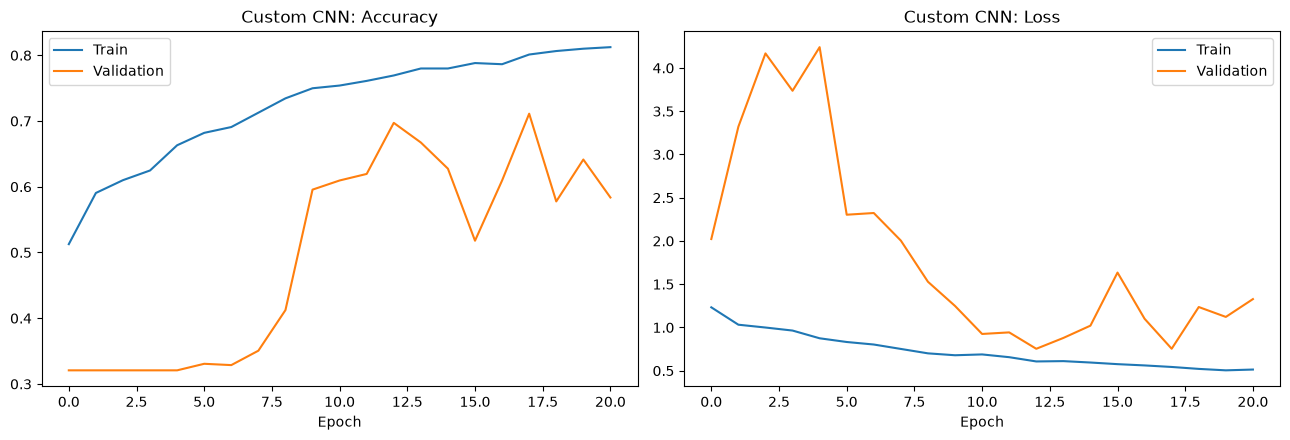

In [6]:
hist = pd.DataFrame(history.history)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(hist["accuracy"], label="Train"); ax[0].plot(hist["val_accuracy"], label="Validation")
ax[0].set_title("Custom CNN: Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["loss"], label="Train"); ax[1].plot(hist["val_loss"], label="Validation")
ax[1].set_title("Custom CNN: Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_custom_cnn_history.png", dpi=150)
plt.show()

# 7: Quick evaluation on validation and test sets

In [7]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Validation -> loss: {val_loss:.4f} | accuracy: {val_acc:.4f}")
print(f"Test       -> loss: {test_loss:.4f} | accuracy: {test_acc:.4f}")

Validation -> loss: 0.7534 | accuracy: 0.6972
Test       -> loss: 0.7711 | accuracy: 0.6626


# 8: Save the final model (.h5)

In [8]:
model.save(str(MODELS_DIR / "custom_cnn.h5"))
print(sorted(p.name for p in MODELS_DIR.iterdir()))

['custom_cnn.h5', 'custom_cnn_best.h5', 'custom_cnn_history.csv']


## Custom CNN Summary
- Architecture: 5 conv blocks (32-64-128-256-256) with BatchNorm, ReLU, MaxPool, Dropout; GlobalAveragePooling; Dense(128) + Dropout(0.5); softmax(4)

- Optimizer: Adam (lr 1e-3) with ReduceLROnPlateau; loss: categorical cross-entropy; class weights used

- Callbacks: EarlyStopping (val_loss, patience 8), ModelCheckpoint (best val_loss)

- Best validation accuracy: 69.7%

- Test accuracy: 66.3%

- Overfitting observations (train vs. validation curves):